# 09 — G10 panel dependence, global-factor attribution, and cross-sectional replication

This notebook asks whether the cross-country evidence is genuinely broader than one global rate cycle
repeated across markets.

It **does not search for a new predictor**. It freezes the macro-anchor pipeline and subjects the
international replication to progressively harder dependence controls:

1. canonical country-by-country replication under the same anchor initialization used in notebook 08;
2. pairwise dependence and common-factor diagnostics;
3. pooled country fixed effects with Driscoll–Kraay inference;
4. country + time fixed effects, which remove every common monthly shock;
5. Fama–MacBeth cross-sectional slopes;
6. leave-one-country-out common-correlated-effects-style mean-group regressions;
7. leave-one-country-out stability;
8. pre-2008, 2008–2015, and post-2016 attribution;
9. anchor-initialization sensitivity.

### Reading rule fixed before the results

- A positive **time-fixed-effect / cross-sectional** coefficient is the strongest evidence that the
  9/10-country sign count is not merely one global episode.
- If only the country-level and global-time components survive, the panel remains useful as international
  comovement evidence but not as independent replication.
- Leave-one-out checks diagnose concentration; they do not make countries independent.
- The international target remains the standard **duration-approximated 10Y excess return**, because
  harmonised foreign zero-coupon curves are not available in this stack.
- All panel estimates are inferential robustness checks. The strict US zero-coupon result from notebook 08
  remains the headline identification result.

### First run and deterministic reruns

The first-run path uses six small browser-downloaded FRED bundles, because a single large graph-export
URL can silently return only a subset of requested series.

1. Run the configuration cell.
2. Run **ONE-TIME LOCAL-BROWSER DOWNLOAD HELPER — SIX SMALL BUNDLES**.
3. Download all six linked CSV files and upload them together to Colab.
4. Run the data-acquisition cell. It recognizes FRED columns, merges the files by date, verifies complete
   coverage and freezes `g10_panel_monthly_snapshot.csv`.

Filenames do not matter. For later deterministic reruns, upload only `g10_panel_monthly_snapshot.csv`,
set `USE_LOCAL_SNAPSHOT = True` and `USE_LOCAL_FRED_BUNDLES = False`.

> **V7 rerun requirement.** Rebuild the panel from the six raw FRED bundles with `USE_LOCAL_SNAPSHOT=False`; the V6 snapshot contains the old quarterly-CPI interpolation and must not be reused for this run.


In [1]:
# ============================================================================
# CONFIGURATION
# ============================================================================
from pathlib import Path
from datetime import datetime, timezone
import io, json, hashlib, platform, shutil, time, warnings, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams.update({"figure.dpi": 115, "font.size": 9, "axes.grid": True, "grid.alpha": 0.25})

START = pd.Timestamp("1960-01-01")
PANEL_END = pd.Timestamp("2026-05-31")
MINW = 120
H = 12
NW_LAG = 12
PI_HL = 36
RSTAR_HL = 120
ANCHOR_INITIALIZATION = "post_ewma_bfill"
QUARTERLY_CPI_RELEASE_LAG_MONTHS = 1

MIN_COUNTRY_MONTHS = MINW + H + 24

USE_LOCAL_SNAPSHOT = False
USE_LOCAL_FRED_BUNDLES = True
ALLOW_NETWORK_BUILD = False
STRICT_MIN_COUNTRIES = 8

SNAPSHOT_FILENAME = "g10_panel_monthly_snapshot.csv"
FRED_BUNDLE_GLOB = "*.csv"
MODEL_PANEL_FILENAME = "g10_panel_model_objects.csv"
OUTPUT_DIR = Path("/content/macroanchor_panel09_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
AUTO_DOWNLOAD_ZIP = True

SEED = 20260712
rng = np.random.default_rng(SEED)

PANEL = {
    "USA": {"y10": "IRLTLT01USM156N", "r3m": "IR3TIB01USM156N",
            "cpi": ["USACPIALLMINMEI", "CPIAUCSL"]},
    "DEU": {"y10": "IRLTLT01DEM156N", "r3m": "IR3TIB01DEM156N",
            "cpi": ["DEUCPIALLMINMEI"]},
    "GBR": {"y10": "IRLTLT01GBM156N", "r3m": "IR3TIB01GBM156N",
            "cpi": ["GBRCPIALLMINMEI"]},
    "JPN": {"y10": "IRLTLT01JPM156N", "r3m": "IR3TIB01JPM156N",
            "cpi": ["JPNCPIALLMINMEI"]},
    "CAN": {"y10": "IRLTLT01CAM156N", "r3m": "IR3TIB01CAM156N",
            "cpi": ["CANCPIALLMINMEI"]},
    "CHE": {"y10": "IRLTLT01CHM156N", "r3m": "IR3TIB01CHM156N",
            "cpi": ["CHECPIALLMINMEI"]},
    "SWE": {"y10": "IRLTLT01SEM156N", "r3m": "IR3TIB01SEM156N",
            "cpi": ["SWECPIALLMINMEI"]},
    "NOR": {"y10": "IRLTLT01NOM156N", "r3m": "IR3TIB01NOM156N",
            "cpi": ["NORCPIALLMINMEI"]},
    "AUS": {"y10": "IRLTLT01AUM156N", "r3m": "IR3TIB01AUM156N",
            "cpi": ["AUSCPIALLQINMEI"]},
    "NZL": {"y10": "IRLTLT01NZM156N", "r3m": "IR3TIB01NZM156N",
            "cpi": ["NZLCPIALLQINMEI"]},
}

print("Canonical panel configuration")
print(" cutoff:", PANEL_END.date())
print(" anchor:", ANCHOR_INITIALIZATION, f"(pi hl={PI_HL}, r* hl={RSTAR_HL})")
print(" minimum country months:", MIN_COUNTRY_MONTHS)


Canonical panel configuration
 cutoff: 2026-05-31
 anchor: post_ewma_bfill (pi hl=36, r* hl=120)
 minimum country months: 156


In [2]:
# ============================================================================
# ONE-TIME LOCAL-BROWSER DOWNLOAD HELPER — SIX SMALL BUNDLES
# ============================================================================
# FRED's graph CSV export may silently omit series when one URL contains too
# many IDs or an invalid ID. This helper therefore creates six small, deterministic bundles.
#
# Workflow:
#   1. Click all six links and download the six CSV files.
#   2. Upload all six CSVs together using the Colab upload control below.
#   3. Run the DATA ACQUISITION cell.
#
# Filenames do NOT matter. The acquisition cell scans uploaded CSV files,
# recognizes the required FRED columns and merges them by date.
#
# After the canonical panel snapshot is created, future runs should use:
#   USE_LOCAL_SNAPSHOT = True
#   USE_LOCAL_FRED_BUNDLES = False

from urllib.parse import urlencode
from IPython.display import display, HTML

BUNDLE_GROUPS = [
    ("Part 1 — USA + Germany", ["USA", "DEU"]),
    ("Part 2 — UK + Japan", ["GBR", "JPN"]),
    ("Part 3 — Canada + Switzerland", ["CAN", "CHE"]),
    ("Part 4 — Sweden + Norway", ["SWE", "NOR"]),
    ("Part 5 — Australia", ["AUS"]),
    ("Part 6 — New Zealand", ["NZL"]),
]

_bundle_specs = []
for label, countries in BUNDLE_GROUPS:
    ids = []
    for country in countries:
        spec = PANEL[country]
        ids.extend([spec["y10"], spec["r3m"]])
        ids.extend(spec["cpi"])
    ids = list(dict.fromkeys(ids))
    url = (
        "https://fred.stlouisfed.org/graph/fredgraph.csv?"
        + urlencode({
            "id": ",".join(ids),
            "cosd": START.strftime("%Y-%m-%d"),
            "coed": PANEL_END.strftime("%Y-%m-%d"),
        })
    )
    _bundle_specs.append((label, countries, ids, url))

links = []
for label, countries, ids, url in _bundle_specs:
    links.append(
        f'<li style="margin:8px 0">'
        f'<a href="{url}" target="_blank" style="font-weight:600">{label}</a>'
        f' &nbsp; <span style="color:#555">({len(ids)} series)</span>'
        f'</li>'
    )

display(HTML(
    """
    <div style="padding:12px;border:1px solid #999;border-radius:8px">
      <b>Step 1 — Download all six fixed FRED bundles in your browser</b>
      <ol>
    """
    + "".join(links)
    + """
      </ol>
      <p>The browser may call them <code>fredgraph.csv</code>,
      <code>fredgraph (1).csv</code>, etc. That is fine.</p>
    </div>
    """
))

print("Bundle plan:")
for label, countries, ids, _ in _bundle_specs:
    print(f"  {label}: {len(ids)} series -> {', '.join(countries)}")

try:
    from google.colab import files
    print("\nStep 2 — upload all six downloaded CSV files together:")
    uploaded = files.upload()
    if uploaded:
        print("Uploaded:", list(uploaded))
except Exception as exc:
    print("Colab upload widget unavailable:", exc)


Bundle plan:
  Part 1 — USA + Germany: 7 series -> USA, DEU
  Part 2 — UK + Japan: 6 series -> GBR, JPN
  Part 3 — Canada + Switzerland: 6 series -> CAN, CHE
  Part 4 — Sweden + Norway: 6 series -> SWE, NOR
  Part 5 — Australia: 3 series -> AUS
  Part 6 — New Zealand: 3 series -> NZL

Step 2 — upload all six downloaded CSV files together:


Saving monthly - Copia.csv to monthly - Copia.csv
Saving quarterly - Copia.csv to quarterly - Copia.csv
Saving monthly.csv to monthly.csv
Saving quarterly.csv to quarterly.csv
Saving fredgraph (3).csv to fredgraph (3).csv
Saving fredgraph (2).csv to fredgraph (2).csv
Saving fredgraph (1).csv to fredgraph (1).csv
Saving fredgraph.csv to fredgraph.csv
Uploaded: ['monthly - Copia.csv', 'quarterly - Copia.csv', 'monthly.csv', 'quarterly.csv', 'fredgraph (3).csv', 'fredgraph (2).csv', 'fredgraph (1).csv', 'fredgraph.csv']


In [3]:
# ============================================================================
# DATA ACQUISITION, MULTI-BUNDLE MERGE, SNAPSHOT AND HASH HELPERS
# ============================================================================
def sha256_file(path):
    path = Path(path)
    h = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

def sha256_frame(df):
    x = df.copy()
    sort_cols = [c for c in ["country", "date"] if c in x.columns]
    if sort_cols:
        x = x.sort_values(sort_cols)
    payload = pd.util.hash_pandas_object(x, index=True).values.tobytes()
    return hashlib.sha256(payload).hexdigest()

def locate_file(name):
    candidates = [Path(name), Path("/content") / name, Path("/mnt/data") / name]
    for p in candidates:
        if p.exists():
            return p
    for root in [Path("/content"), Path.cwd()]:
        if root.exists():
            found = list(root.rglob(name))
            if found:
                return found[0]
    return None

def required_fred_series():
    ids = []
    for spec in PANEL.values():
        ids.extend([spec["y10"], spec["r3m"]])
        ids.extend(spec["cpi"])
    return list(dict.fromkeys(ids))

def _read_candidate_fred_csv(path):
    """
    Read an uploaded CSV and return a date-indexed frame only when it contains
    at least one required FRED series. Unrelated CSVs are ignored.
    """
    path = Path(path)
    try:
        raw = pd.read_csv(path)
    except Exception:
        return None

    if raw.empty or raw.shape[1] < 2:
        return None

    required = set(required_fred_series())
    matching = [c for c in raw.columns if c in required]
    if not matching:
        return None

    date_col = raw.columns[0]
    dates = pd.to_datetime(raw[date_col], errors="coerce")
    out = raw.loc[dates.notna(), matching].copy()
    out.index = dates.loc[dates.notna()]
    out.index.name = "date"
    for c in out.columns:
        out[c] = pd.to_numeric(out[c], errors="coerce")
    out = out.sort_index()
    return out

def discover_and_merge_fred_bundles():
    """
    Scan uploaded CSVs, retain only files containing required FRED columns,
    and merge them by date. Duplicate columns are combined using first
    non-missing values; conflicting non-missing observations raise an error.
    """
    roots = [Path("/content"), Path.cwd(), Path("/mnt/data")]
    candidates = []
    seen = set()

    for root in roots:
        if not root.exists():
            continue
        for path in root.glob(FRED_BUNDLE_GLOB):
            resolved = str(path.resolve())
            if resolved in seen:
                continue
            seen.add(resolved)

            # Never ingest the already-built canonical outputs as raw bundles.
            if path.name in {SNAPSHOT_FILENAME, MODEL_PANEL_FILENAME}:
                continue

            frame = _read_candidate_fred_csv(path)
            if frame is not None:
                candidates.append((path, frame))

    if not candidates:
        raise FileNotFoundError(
            "No uploaded CSV containing required FRED series was found. "
            "Run the six-part browser-download helper and upload all six files."
        )

    print("Recognized FRED bundle files:")
    for path, frame in candidates:
        print(f"  {path.name}: {len(frame.columns)} matching series")

    merged = pd.DataFrame()
    source_files = []

    for path, frame in candidates:
        source_files.append({
            "path": str(path),
            "sha256": sha256_file(path),
            "series": list(frame.columns),
        })

        if merged.empty:
            merged = frame.copy()
            continue

        merged = merged.reindex(merged.index.union(frame.index)).sort_index()
        frame = frame.reindex(merged.index)

        for col in frame.columns:
            if col not in merged.columns:
                merged[col] = frame[col]
                continue

            both = merged[col].notna() & frame[col].notna()
            if both.any():
                disagreement = (
                    (merged.loc[both, col] - frame.loc[both, col]).abs() > 1e-12
                )
                if disagreement.any():
                    first_bad = disagreement[disagreement].index[0]
                    raise ValueError(
                        f"Conflicting values for {col} at {first_bad.date()} "
                        f"between uploaded bundle files."
                    )
            merged[col] = merged[col].combine_first(frame[col])

    required = set(required_fred_series())
    present = set(merged.columns)
    missing = sorted(required - present)

    print(f"\nMerged unique FRED series: {len(present)} / {len(required)}")
    if missing:
        raise ValueError(
            "Uploaded bundles are incomplete. Missing series:\n  "
            + "\n  ".join(missing)
            + "\nDownload/upload all six bundle parts, then rerun this cell."
        )

    return merged.sort_index(), source_files

def monthly_cpi_from_source(cpi, series_id):
    """
    Convert a FRED CPI series to a monthly information set.

    Monthly sources retain their reported month-end observation. Quarterly
    AUS/NZL sources are treated conservatively: each quarter's value becomes
    available at quarter-end plus one month and is then carried forward.
    This removes the two-month interpolation look-ahead present in V6.
    """
    cpi = cpi.dropna().sort_index().astype(float)

    if "QINMEI" in str(series_id).upper():
        quarter_end = cpi.index.to_period("Q").to_timestamp(how="end").normalize()
        release_date = quarter_end + pd.offsets.MonthEnd(
            QUARTERLY_CPI_RELEASE_LAG_MONTHS
        )
        released = pd.Series(cpi.to_numpy(), index=release_date)
        released = released.groupby(level=0).last().sort_index()
        monthly = released.resample("ME").last().ffill()
        method = (
            f"quarter_end_plus_{QUARTERLY_CPI_RELEASE_LAG_MONTHS}m_"
            "release_lag_then_ffill"
        )
    else:
        monthly = cpi.resample("ME").last()
        method = "monthly_period_end"

    return monthly, method


def build_snapshot_from_bundles():
    wide, source_files = discover_and_merge_fred_bundles()

    rows = []
    source_log = {
        "mode": "local_fred_multi_bundle",
        "bundle_files": source_files,
    }
    failures = {}

    for country, ids in PANEL.items():
        try:
            y = wide[ids["y10"]].dropna()
            r = wide[ids["r3m"]].dropna()

            cpi = None
            chosen_cpi = None
            cpi_errors = []
            for cpi_id in ids["cpi"]:
                if cpi_id not in wide.columns:
                    cpi_errors.append(f"{cpi_id}: absent")
                    continue
                candidate = wide[cpi_id].dropna()
                if candidate.notna().sum() >= 24:
                    cpi = candidate
                    chosen_cpi = cpi_id
                    break
                cpi_errors.append(
                    f"{cpi_id}: only {candidate.notna().sum()} observations"
                )

            if cpi is None:
                raise RuntimeError(
                    "No pre-specified CPI source available; "
                    + " | ".join(cpi_errors)
                )

            cpi_monthly, cpi_monthly_method = monthly_cpi_from_source(
                cpi, chosen_cpi
            )

            df = pd.DataFrame({
                "y10": y.resample("ME").last() / 100.0,
                "r3m": r.resample("ME").last() / 100.0,
                "cpi": cpi_monthly,
            })
            df = df.loc[(df.index >= START) & (df.index <= PANEL_END)].dropna()

            if len(df) < MIN_COUNTRY_MONTHS:
                raise RuntimeError(
                    f"only {len(df)} complete monthly rows; "
                    f"minimum required={MIN_COUNTRY_MONTHS}"
                )

            source_log[country] = {
                "y10": ids["y10"],
                "r3m": ids["r3m"],
                "cpi": chosen_cpi,
                "cpi_monthly_method": cpi_monthly_method,
                "start": str(df.index.min().date()),
                "end": str(df.index.max().date()),
                "rows": int(len(df)),
            }

            out = df.reset_index()
            out.insert(1, "country", country)
            rows.append(out)
            print(
                f"[{country}] OK — {len(df)} months, "
                f"{df.index.min().date()} to {df.index.max().date()}, "
                f"CPI={chosen_cpi}"
            )

        except Exception as exc:
            failures[country] = str(exc)
            print(f"[{country}] FAILED — {exc}")

    if not rows:
        detail = "\n".join(f"  {k}: {v}" for k, v in failures.items())
        raise RuntimeError(
            "No country data could be assembled from the uploaded bundles.\n"
            "Country-level failures:\n" + detail
        )

    panel = pd.concat(rows, ignore_index=True)
    panel["date"] = pd.to_datetime(panel["date"])
    panel = panel.sort_values(["country", "date"]).reset_index(drop=True)

    n_countries = panel["country"].nunique()
    if n_countries < STRICT_MIN_COUNTRIES:
        detail = "\n".join(f"  {k}: {v}" for k, v in failures.items())
        raise RuntimeError(
            f"Only {n_countries} countries assembled, below "
            f"STRICT_MIN_COUNTRIES={STRICT_MIN_COUNTRIES}.\n"
            f"Country-level failures:\n{detail}"
        )

    snapshot_path = Path("/content") / SNAPSHOT_FILENAME
    panel.to_csv(snapshot_path, index=False)
    source_log["panel_snapshot_path"] = str(snapshot_path)
    source_log["panel_snapshot_sha256"] = sha256_file(snapshot_path)

    print("\nCreated deterministic panel snapshot:", snapshot_path)
    print("SHA-256:", source_log["panel_snapshot_sha256"])
    return panel, source_log, failures

def load_or_build_snapshot():
    snapshot_path = locate_file(SNAPSHOT_FILENAME)

    if USE_LOCAL_SNAPSHOT:
        if snapshot_path is None:
            raise FileNotFoundError(
                f"USE_LOCAL_SNAPSHOT=True but {SNAPSHOT_FILENAME} was not found. "
                "Upload it to the Colab runtime."
            )
        panel = pd.read_csv(snapshot_path, parse_dates=["date"])
        required = {"date", "country", "y10", "r3m", "cpi"}
        if not required.issubset(panel.columns):
            raise ValueError(
                f"Snapshot missing columns: {required - set(panel.columns)}"
            )
        source_log = {
            "mode": "local_snapshot",
            "path": str(snapshot_path),
            "sha256": sha256_file(snapshot_path),
        }
        failures = {}
        print("Loaded local panel snapshot:", snapshot_path)

    elif USE_LOCAL_FRED_BUNDLES:
        panel, source_log, failures = build_snapshot_from_bundles()

    else:
        raise RuntimeError(
            "No local input mode is active. Set either "
            "USE_LOCAL_SNAPSHOT=True or USE_LOCAL_FRED_BUNDLES=True."
        )

    panel = panel.loc[panel["date"] <= PANEL_END].copy()
    panel = panel.sort_values(["country", "date"]).reset_index(drop=True)
    return panel, source_log, failures

raw_panel, source_log, source_failures = load_or_build_snapshot()

print("\nAssembled countries:", sorted(raw_panel["country"].unique()))
print(pd.DataFrame({
    c: {
        "start": str(g["date"].min().date()),
        "end": str(g["date"].max().date()),
        "months": len(g),
    }
    for c, g in raw_panel.groupby("country")
}).T.to_string())

if source_failures:
    print("\nExplicitly excluded / unavailable:")
    for k, v in source_failures.items():
        print(" ", k, "->", v)


Recognized FRED bundle files:
  fredgraph (1).csv: 6 matching series
  fredgraph.csv: 7 matching series
  fredgraph (3).csv: 6 matching series
  quarterly - Copia.csv: 1 matching series
  monthly - Copia.csv: 2 matching series
  monthly.csv: 2 matching series
  quarterly.csv: 1 matching series
  fredgraph (2).csv: 6 matching series

Merged unique FRED series: 31 / 31
[USA] OK — 730 months, 1964-06-30 to 2025-04-30, CPI=USACPIALLMINMEI
[DEU] OK — 783 months, 1960-01-31 to 2025-03-31, CPI=DEUCPIALLMINMEI
[GBR] OK — 783 months, 1960-01-31 to 2025-03-31, CPI=GBRCPIALLMINMEI
[JPN] OK — 231 months, 2002-04-30 to 2021-06-30, CPI=JPNCPIALLMINMEI
[CAN] OK — 783 months, 1960-01-31 to 2025-03-31, CPI=CANCPIALLMINMEI
[CHE] OK — 310 months, 1999-07-31 to 2025-04-30, CPI=CHECPIALLMINMEI
[SWE] OK — 460 months, 1986-12-31 to 2025-03-31, CPI=SWECPIALLMINMEI
[NOR] OK — 484 months, 1985-01-31 to 2025-04-30, CPI=NORCPIALLMINMEI
[AUS] OK — 670 months, 1969-07-31 to 2025-04-30, CPI=AUSCPIALLQINMEI
[NZL] OK 

In [4]:
# ============================================================================
# MODEL, FORECAST AND INFERENCE HELPERS
# ============================================================================
def vas_B(tau, kappa):
    kappa = max(float(kappa), 1e-4)
    return (1.0 - np.exp(-kappa * tau)) / kappa

def vas_yield(tau, short_rate, kappa, theta, sigma):
    kappa = max(float(kappa), 1e-4)
    B = vas_B(tau, kappa)
    lnA = (theta - sigma * sigma / (2 * kappa * kappa)) * (B - tau) \
          - sigma * sigma * B * B / (4 * kappa)
    return (-lnA + B * short_rate) / tau

def build_anchor(df, initialization=ANCHOR_INITIALIZATION, pi_hl=PI_HL, rstar_hl=RSTAR_HL):
    idx = pd.DatetimeIndex(df.index)
    short_s = pd.Series(df["r3m"].to_numpy(float), index=idx)
    cpi_s = pd.Series(df["cpi"].to_numpy(float), index=idx)
    pi_raw = cpi_s.pct_change(12).ewm(halflife=pi_hl).mean()

    if initialization == "draft_pre_rstar_bfill":
        pi = pi_raw.bfill()
        rstar = (short_s - pi).ewm(halflife=rstar_hl).mean().bfill()
    elif initialization in ("post_ewma_bfill", "strict"):
        pi = pi_raw
        rstar = (short_s - pi).ewm(halflife=rstar_hl).mean()
        if initialization == "post_ewma_bfill":
            pi = pi.bfill()
            rstar = rstar.bfill()
    else:
        raise ValueError("Unknown anchor initialization.")
    anchor = rstar + pi
    return anchor, rstar, pi

def past_only_z(x, minobs=MINW):
    x = np.asarray(x, float)
    z = np.full(len(x), np.nan)
    for t in range(minobs, len(x)):
        hist = x[:t]
        hist = hist[np.isfinite(hist)]
        if len(hist) < minobs or not np.isfinite(x[t]):
            continue
        sd = hist.std(ddof=1)
        if sd > 1e-12:
            z[t] = (x[t] - hist.mean()) / sd
    return z

def run_country_objects(df, initialization=ANCHOR_INITIALIZATION):
    df = df.sort_index().copy()
    n = len(df)
    r = df["r3m"].to_numpy(float)
    y10 = df["y10"].to_numpy(float)
    anchor, rstar, pi = build_anchor(df, initialization=initialization)
    anc = anchor.to_numpy(float)

    kappa = np.full(n, np.nan)
    sigma = np.full(n, np.nan)
    tp = np.full(n, np.nan)

    for t in range(MINW, n):
        g = anc[:t] - r[:t]
        dr = r[1:t + 1] - r[:t]
        m = np.isfinite(g) & np.isfinite(dr)
        if m.sum() < MINW:
            continue
        X = np.column_stack([np.ones(m.sum()), g[m]])
        a0, slope_coef = np.linalg.lstsq(X, dr[m], rcond=None)[0]
        kappa[t] = float(np.clip(slope_coef * 12.0, 1e-4, 20.0))
        resid = dr[m] - (a0 + slope_coef * g[m])
        sigma[t] = float(np.std(resid, ddof=0) * np.sqrt(12.0))
        tp[t] = y10[t] - vas_yield(10.0, r[t], kappa[t], anc[t], sigma[t])

    y_safe = np.maximum(y10, 1e-4)
    duration = (1.0 - (1.0 + y_safe) ** -10) / y_safe
    rx = np.full(n, np.nan)
    for t in range(n - H):
        rx[t] = y10[t] - duration[t] * (y10[t + H] - y10[t]) - r[t]

    return pd.DataFrame({
        "date": df.index,
        "country": df["country"].iloc[0],
        "y10": y10,
        "r3m": r,
        "slope": y10 - r,
        "pi_trend": pi.to_numpy(float),
        "rstar": rstar.to_numpy(float),
        "anchor": anc,
        "kappa": kappa,
        "sigma": sigma,
        "tp": tp,
        "tp_z_past": past_only_z(tp),
        "rx": rx,
    })

def nw_ols(y, X, lag=NW_LAG, add_intercept=True, return_cov=False):
    y = np.asarray(y, float)
    X = np.asarray(X, float)
    if X.ndim == 1:
        X = X[:, None]
    m = np.isfinite(y) & np.isfinite(X).all(axis=1)
    y = y[m]
    X = X[m]
    if add_intercept:
        X = np.column_stack([np.ones(len(y)), X])
    beta = np.linalg.lstsq(X, y, rcond=None)[0]
    e = y - X @ beta
    bread = np.linalg.pinv(X.T @ X)
    score = X * e[:, None]
    S = score.T @ score
    for ell in range(1, min(lag, len(y) - 1) + 1):
        w = 1.0 - ell / (lag + 1.0)
        G = score[ell:].T @ score[:-ell]
        S += w * (G + G.T)
    V = bread @ S @ bread
    se = np.sqrt(np.maximum(np.diag(V), 0))
    denom = np.sum((y - y.mean()) ** 2)
    r2 = 1.0 - np.sum(e * e) / denom if denom > 0 else np.nan
    if return_cov:
        return beta, se, V, r2, int(len(y))
    return beta, se, r2, int(len(y))

def oos_stats(signal, target, minobs=MINW, horizon=H):
    signal = np.asarray(signal, float)
    target = np.asarray(target, float)
    if signal.ndim == 1:
        signal = signal[:, None]
    e_model, e_mean, adjusted = [], [], []
    for t in range(minobs + horizon, len(target)):
        if not np.isfinite(target[t]) or not np.isfinite(signal[t]).all():
            continue
        train = np.arange(0, t - horizon + 1)
        m = np.isfinite(target[train]) & np.isfinite(signal[train]).all(axis=1)
        if m.sum() < minobs:
            continue
        ytr = target[train][m]
        Xtr = np.column_stack([np.ones(m.sum()), signal[train][m]])
        b = np.linalg.lstsq(Xtr, ytr, rcond=None)[0]
        f_model = float(np.r_[1.0, signal[t]] @ b)
        f_mean = float(ytr.mean())
        em = target[t] - f_model
        eb = target[t] - f_mean
        e_model.append(em)
        e_mean.append(eb)
        adjusted.append(eb * eb - (em * em - (f_mean - f_model) ** 2))
    if len(e_model) < 24:
        return {"OOS_R2": np.nan, "CW_t": np.nan, "n_eval": len(e_model)}
    em = np.asarray(e_model)
    eb = np.asarray(e_mean)
    f = np.asarray(adjusted)
    oos = 1.0 - np.sum(em * em) / np.sum(eb * eb)
    b, se, _, n = nw_ols(f, np.empty((len(f), 0)), lag=NW_LAG, add_intercept=True)
    return {"OOS_R2": oos, "CW_t": b[0] / se[0], "n_eval": n}

def alternating_absorb(df, cols, groups, tol=1e-11, max_iter=500):
    z = df[cols].astype(float).copy()
    for _ in range(max_iter):
        old = z.to_numpy(copy=True)
        for g in groups:
            z = z - z.groupby(df[g]).transform("mean")
        diff = np.nanmax(np.abs(z.to_numpy() - old))
        if diff < tol:
            break
    return z

def driscoll_kraay(y, X, dates, lag=NW_LAG, return_cov=False):
    y = np.asarray(y, float)
    X = np.asarray(X, float)
    dates = pd.to_datetime(np.asarray(dates))
    if X.ndim == 1:
        X = X[:, None]
    m = np.isfinite(y) & np.isfinite(X).all(axis=1) & pd.notna(dates)
    y, X, dates = y[m], X[m], dates[m]
    beta = np.linalg.lstsq(X, y, rcond=None)[0]
    e = y - X @ beta
    bread = np.linalg.pinv(X.T @ X)

    score_df = pd.DataFrame(X * e[:, None])
    score_df["date"] = dates
    G = score_df.groupby("date").sum().sort_index().to_numpy(float)
    S = G.T @ G
    for ell in range(1, min(lag, len(G) - 1) + 1):
        w = 1.0 - ell / (lag + 1.0)
        Gamma = G[ell:].T @ G[:-ell]
        S += w * (Gamma + Gamma.T)
    V = bread @ S @ bread
    T = len(np.unique(dates))
    k = X.shape[1]
    if T > k:
        V *= T / (T - k)
    se = np.sqrt(np.maximum(np.diag(V), 0))
    if return_cov:
        return beta, se, V, int(len(y)), int(T)
    return beta, se, int(len(y)), int(T)

def panel_fe_dk(df, y_col, x_cols, entity_fe=True, time_fe=False, lag=NW_LAG):
    d = df[["date", "country", y_col] + list(x_cols)].dropna().copy()
    cols = [y_col] + list(x_cols)
    groups = []
    if entity_fe:
        groups.append("country")
    if time_fe:
        groups.append("date")
    z = alternating_absorb(d, cols, groups) if groups else d[cols].astype(float)
    y = z[y_col].to_numpy(float)
    X = z[list(x_cols)].to_numpy(float)
    b, se, n, T = driscoll_kraay(y, X, d["date"], lag=lag)
    return {"beta": b[0], "se_DK": se[0], "t_DK": b[0] / se[0], "n": n, "T": T}

def panel_fe_dk_full(
    df, y_col, x_cols, entity_fe=True, time_fe=False, lag=NW_LAG
):
    """Multivariate FE regression with the full Driscoll–Kraay covariance."""
    d = df[["date", "country", y_col] + list(x_cols)].dropna().copy()
    cols = [y_col] + list(x_cols)
    groups = []
    if entity_fe:
        groups.append("country")
    if time_fe:
        groups.append("date")
    z = alternating_absorb(d, cols, groups) if groups else d[cols].astype(float)
    y = z[y_col].to_numpy(float)
    X = z[list(x_cols)].to_numpy(float)
    b, se, V, n, T = driscoll_kraay(
        y, X, d["date"], lag=lag, return_cov=True
    )
    return {
        "beta": pd.Series(b, index=x_cols, dtype=float),
        "se_DK": pd.Series(se, index=x_cols, dtype=float),
        "cov_DK": pd.DataFrame(V, index=x_cols, columns=x_cols, dtype=float),
        "n": n,
        "T": T,
    }


def pairwise_wald_table(beta, cov, labels, model_name):
    """Two-sided pairwise Wald tests for pre-specified slope differences."""
    beta = pd.Series(beta, index=labels, dtype=float)
    cov = pd.DataFrame(cov, index=labels, columns=labels, dtype=float)
    rows = []
    for i in range(len(labels)):
        for j in range(i + 1, len(labels)):
            a, b = labels[i], labels[j]
            diff = float(beta[a] - beta[b])
            var = float(cov.loc[a, a] + cov.loc[b, b] - 2.0 * cov.loc[a, b])
            se = math.sqrt(max(var, 0.0))
            t_stat = diff / se if se > 0 else np.nan
            p_value = math.erfc(abs(t_stat) / math.sqrt(2.0)) \
                if np.isfinite(t_stat) else np.nan
            rows.append({
                "model": model_name,
                "contrast": f"{a} - {b}",
                "difference": diff,
                "se": se,
                "t": t_stat,
                "p_two_sided_normal": p_value,
            })
    return pd.DataFrame(rows)


def fmb_cross_section(df, y_col="rx", x_col="tp_z_past", min_countries=5, lag=NW_LAG):
    slopes = []
    for date, g in df.groupby("date"):
        g = g[[y_col, x_col]].dropna()
        if len(g) < min_countries or g[x_col].std(ddof=1) < 1e-10:
            continue
        X = np.column_stack([np.ones(len(g)), g[x_col].to_numpy()])
        b = np.linalg.lstsq(X, g[y_col].to_numpy(), rcond=None)[0]
        slopes.append((date, b[1], len(g)))
    s = pd.DataFrame(slopes, columns=["date", "beta_cs", "n_countries"]).set_index("date")
    b, se, _, n = nw_ols(s["beta_cs"].to_numpy(), np.empty((len(s), 0)), lag=lag, add_intercept=True)
    return s, {"beta": b[0], "se_NW": se[0], "t_NW": b[0] / se[0], "months": n}

def largest_balanced_matrix(df, value, min_obs=120, min_countries=4):
    piv = df.pivot(index="date", columns="country", values=value).sort_index()
    cols = list(piv.columns)
    while len(cols) >= min_countries:
        complete = piv[cols].dropna()
        if len(complete) >= min_obs:
            return complete
        scores = []
        for c in cols:
            s = piv[c].dropna()
            first = s.index.min() if len(s) else pd.Timestamp.max
            scores.append((first, -len(s), c))
        cols.remove(max(scores)[2])
    return pd.DataFrame()

def pc1_share(matrix):
    if matrix.empty:
        return np.nan
    z = (matrix - matrix.mean()) / matrix.std(ddof=1)
    z = z.dropna()
    if len(z) < 24:
        return np.nan
    _, s, _ = np.linalg.svd(z.to_numpy(), full_matrices=False)
    return float((s[0] ** 2) / np.sum(s ** 2))


## Synthetic self-test

The synthetic panel contains a persistent common shock that is correlated with the predictor plus a genuine
cross-sectional signal. The test verifies that two-way absorption works, the dependence-robust routines
return finite inference, and future observations cannot alter past-only standardisation.


In [5]:
# ============================================================================
# SYNTHETIC SELF-TEST
# ============================================================================
def synthetic_panel(T=300, N=8, beta_true=0.02):
    dates = pd.date_range("1990-01-31", periods=T, freq="ME")
    countries = [f"C{i}" for i in range(N)]
    common = np.zeros(T)
    for t in range(1, T):
        common[t] = 0.85 * common[t - 1] + rng.normal(scale=0.7)
    rows = []
    for c in countries:
        x_idio = rng.normal(size=T)
        x = 0.8 * common + x_idio
        y = beta_true * x_idio + 0.04 * common + rng.normal(scale=0.06, size=T)
        rows.extend((dt, c, x[t], y[t]) for t, dt in enumerate(dates))
    return pd.DataFrame(rows, columns=["date", "country", "tp_z_past", "rx"])

syn = synthetic_panel()
absorbed = alternating_absorb(syn, ["rx", "tp_z_past"], ["country", "date"])
tmp = syn[["date", "country"]].copy()
tmp[["rx", "tp_z_past"]] = absorbed
assert tmp.groupby("country")[["rx", "tp_z_past"]].mean().abs().to_numpy().max() < 1e-8
assert tmp.groupby("date")[["rx", "tp_z_past"]].mean().abs().to_numpy().max() < 1e-8

tw = panel_fe_dk(syn, "rx", ["tp_z_past"], entity_fe=True, time_fe=True)
_, fmb = fmb_cross_section(syn)
assert np.isfinite(tw["t_DK"]) and tw["beta"] > 0
assert np.isfinite(fmb["t_NW"]) and fmb["beta"] > 0

x = rng.normal(size=250)
z0 = past_only_z(x, minobs=60)
x2 = x.copy()
x2[220:] += 1000
z1 = past_only_z(x2, minobs=60)
assert np.allclose(z0[:220], z1[:220], equal_nan=True)

print("SELF-TEST OK")
print(" two-way FE beta:", round(tw["beta"], 4), "| DK t:", round(tw["t_DK"], 2))
print(" Fama–MacBeth beta:", round(fmb["beta"], 4), "| NW t:", round(fmb["t_NW"], 2))


SELF-TEST OK
 two-way FE beta: 0.0222 | DK t: 23.36
 Fama–MacBeth beta: 0.0221 | NW t: 17.25


## Construct the frozen macro-anchor panel

The signal is estimated country by country with expanding windows. Predictor scaling is strictly past-only,
so cross-country comparisons at date \(t\) do not use future predictor observations.


In [6]:
# ============================================================================
# BUILD COUNTRY OBJECTS
# ============================================================================
objects = []
for country, g in raw_panel.groupby("country"):
    d = g.sort_values("date").set_index("date").copy()
    d["country"] = country
    objects.append(run_country_objects(d, initialization=ANCHOR_INITIALIZATION))

model_panel = pd.concat(objects, ignore_index=True)
model_panel["date"] = pd.to_datetime(model_panel["date"])
analysis_panel = model_panel.dropna(subset=["rx", "tp", "tp_z_past"]).copy()

print("Model panel:", analysis_panel["country"].nunique(), "countries,",
      len(analysis_panel), "country-month observations")
print(pd.DataFrame({
    c: {
        "start": str(g["date"].min().date()),
        "end": str(g["date"].max().date()),
        "usable": len(g),
        "last_kappa": g["kappa"].dropna().iloc[-1] if g["kappa"].notna().any() else np.nan,
    }
    for c, g in analysis_panel.groupby("country")
}).T.to_string())


Model panel: 9 countries, 3351 country-month observations
          start         end usable last_kappa
AUS  1989-07-31  2024-04-30    418     0.3155
CAN  1980-01-31  2024-03-31    531     0.1602
CHE  2019-07-31  2024-04-30     58     0.0053
DEU  1980-01-31  2024-03-31    531     0.0001
GBR  1980-01-31  2024-03-31    531     0.0760
NOR  2005-01-31  2024-04-30    232     0.3223
NZL  1994-01-31  2024-04-30    364     0.1991
SWE  2006-12-31  2024-03-31    208     0.7663
USA  1984-06-30  2024-04-30    478     0.2220


## 1. Canonical country-by-country replication

The sign count is descriptive because countries are dependent. It is retained for continuity with the draft,
then progressively discounted by the dependence controls below.


         beta_perSD   NW_t  IS_R2  OOS_R2    CW_t  n_eval  last_kappa
country                                                              
CAN          0.0378 6.0017 0.2300  0.2507  4.6137     520      0.1690
USA          0.0468 5.6580 0.2898  0.2158  4.7529     467      0.2274
SWE          0.0319 4.2174 0.2059  0.1991  3.1795     197      0.7776
DEU          0.0243 3.3271 0.1082  0.0037  1.5710     520      0.0001
NOR          0.0229 3.1294 0.1285 -0.0585  1.6802     221      0.3062
CHE          0.0208 2.0198 0.1367 -0.3557  0.4824      47      0.0716
AUS          0.0167 2.0077 0.0387 -0.1378 -0.7207     407      0.3157
NZL          0.0264 1.8030 0.0710  0.1009  2.9014     353      0.1947
GBR          0.0142 1.4861 0.0265  0.0222  1.7410     520      0.0781

Sign count: 9 / 9
Positive OOS R2: 6 / 9
CW > 1.282: 7 / 9


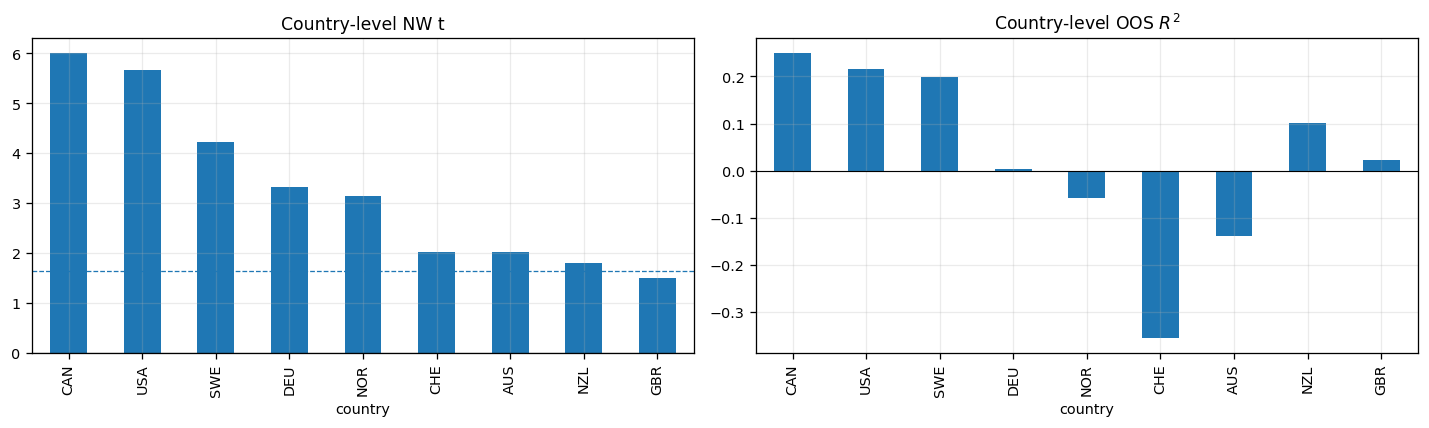

In [7]:
# ============================================================================
# BASELINE COUNTRY-BY-COUNTRY RESULTS
# ============================================================================
baseline_rows = []
for country, g in model_panel.groupby("country"):
    m = g["rx"].notna() & g["tp"].notna()
    if m.sum() < MINW + 24:
        continue
    sd = g.loc[m, "tp"].std(ddof=1)
    z_full = g["tp"] / sd if sd > 1e-12 else g["tp"] * np.nan
    b, se, r2, _ = nw_ols(g.loc[m, "rx"], z_full.loc[m], lag=NW_LAG)
    oos = oos_stats(g["tp"].to_numpy(), g["rx"].to_numpy())
    baseline_rows.append({
        "country": country,
        "beta_perSD": b[1],
        "NW_t": b[1] / se[1],
        "IS_R2": r2,
        **oos,
        "last_kappa": g["kappa"].dropna().iloc[-1],
    })

baseline = pd.DataFrame(baseline_rows).set_index("country").sort_values("NW_t", ascending=False)
print(baseline.to_string())
print("\nSign count:", int((baseline["beta_perSD"] > 0).sum()), "/", len(baseline))
print("Positive OOS R2:", int((baseline["OOS_R2"] > 0).sum()), "/", len(baseline))
print("CW > 1.282:", int((baseline["CW_t"] > 1.282).sum()), "/", len(baseline))

fig, ax = plt.subplots(1, 2, figsize=(12.5, 3.8))
baseline["NW_t"].plot.bar(ax=ax[0], title="Country-level NW t")
ax[0].axhline(0, lw=0.7, color="black")
ax[0].axhline(1.645, lw=0.8, ls="--")
baseline["OOS_R2"].plot.bar(ax=ax[1], title="Country-level OOS $R^2$")
ax[1].axhline(0, lw=0.7, color="black")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "figure_country_replication.png", bbox_inches="tight")
plt.show()


## 2. How global is the panel?

Pairwise correlations and first-principal-component shares measure common variation. They do not test
predictability; they quantify how aggressively the country sign count must be discounted.


           median_pairwise_corr  mean_pairwise_corr  pc1_share  balanced_months               balanced_countries
variable                                                                                                        
rx                       0.8517              0.8502     0.8914              207  AUS,CAN,DEU,GBR,NOR,NZL,SWE,USA
tp_z_past                0.5367              0.5384     0.6250              207  AUS,CAN,DEU,GBR,NOR,NZL,SWE,USA
y10                      0.9594              0.9491     0.9408              207  AUS,CAN,DEU,GBR,NOR,NZL,SWE,USA
slope                    0.5883              0.5898     0.7839              207  AUS,CAN,DEU,GBR,NOR,NZL,SWE,USA


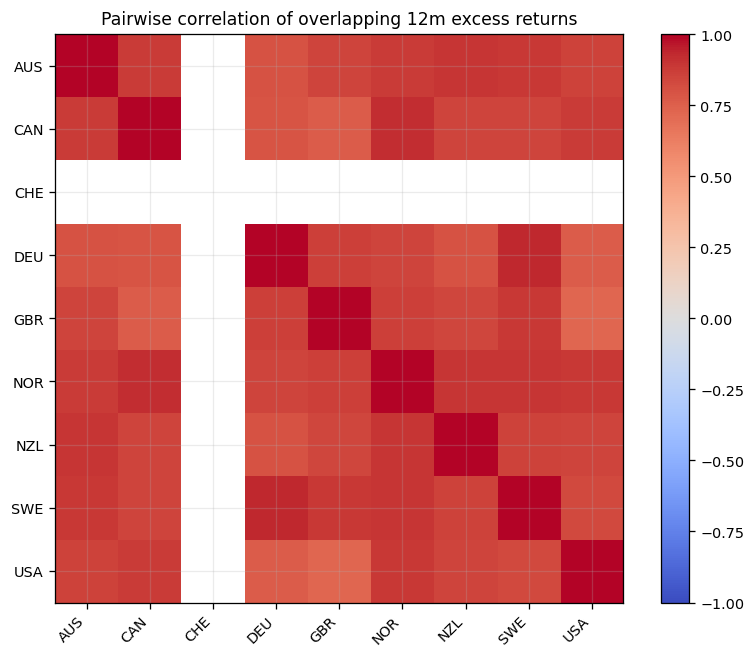

In [8]:
# ============================================================================
# DEPENDENCE AND COMMON-FACTOR DIAGNOSTICS
# ============================================================================
dep_rows = []
dep_objects = {}
for value in ["rx", "tp_z_past", "y10", "slope"]:
    piv = analysis_panel.pivot(index="date", columns="country", values=value)
    corr = piv.corr(min_periods=60)
    vals = corr.to_numpy()[np.triu_indices_from(corr, k=1)]
    balanced = largest_balanced_matrix(analysis_panel, value=value, min_obs=120)
    dep_rows.append({
        "variable": value,
        "median_pairwise_corr": np.nanmedian(vals),
        "mean_pairwise_corr": np.nanmean(vals),
        "pc1_share": pc1_share(balanced),
        "balanced_months": len(balanced),
        "balanced_countries": ",".join(map(str, balanced.columns)),
    })
    dep_objects[value] = (corr, balanced)

dependence = pd.DataFrame(dep_rows).set_index("variable")
print(dependence.to_string())

fig, ax = plt.subplots(figsize=(7.2, 5.8))
im = ax.imshow(dep_objects["rx"][0], vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(dep_objects["rx"][0].columns)))
ax.set_yticks(range(len(dep_objects["rx"][0].index)))
ax.set_xticklabels(dep_objects["rx"][0].columns, rotation=45, ha="right")
ax.set_yticklabels(dep_objects["rx"][0].index)
ax.set_title("Pairwise correlation of overlapping 12m excess returns")
plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "figure_rx_correlation_heatmap.png", bbox_inches="tight")
plt.show()


## 3. Panel inference under progressively harder common-shock controls

- **Country FE only:** uses within-country time variation but leaves global time shocks intact.
- **Country + time FE:** removes every common monthly component from signal and target.
- **Country FE + leave-one-out global controls:** controls parametrically for global signal, return, level,
  and slope without using the country itself in the global averages.

Driscoll–Kraay standard errors use 12 lags.


In [9]:
# ============================================================================
# GLOBAL LEAVE-ONE-OUT CONTROLS AND PANEL MODELS
# ============================================================================
p = analysis_panel.copy()
for col in ["rx", "tp_z_past", "y10", "slope"]:
    count = p.groupby("date")[col].transform("count")
    total = p.groupby("date")[col].transform("sum")
    p[f"global_{col}_loo"] = np.where(count > 1, (total - p[col]) / (count - 1), np.nan)

panel_models = []
panel_models.append({"model": "Country FE",
                     **panel_fe_dk(p, "rx", ["tp_z_past"], entity_fe=True, time_fe=False)})
panel_models.append({"model": "Country + time FE",
                     **panel_fe_dk(p, "rx", ["tp_z_past"], entity_fe=True, time_fe=True)})

global_controls = ["tp_z_past", "global_tp_z_past_loo", "global_rx_loo",
                   "global_y10_loo", "global_slope_loo"]
panel_models.append({"model": "Country FE + LOO global controls",
                     **panel_fe_dk(p, "rx", global_controls, entity_fe=True, time_fe=False)})

panel_table = pd.DataFrame(panel_models).set_index("model")
print(panel_table.to_string())
print("\nPrimary dependence verdict: read the Country + time FE row first.")


                                   beta  se_DK   t_DK     n    T
model                                                           
Country FE                       0.0331 0.0061 5.4668  3351  532
Country + time FE                0.0185 0.0038 4.8351  3351  532
Country FE + LOO global controls 0.0195 0.0041 4.7533  3351  532

Primary dependence verdict: read the Country + time FE row first.


## 4. Fama–MacBeth cross-sectional replication

Each month, the regression compares countries with high versus low macro-anchored signals. The average
cross-sectional slope is tested through time with Newey–West(12). This removes all common monthly return
shocks by construction and complements the two-way fixed-effect result.


beta       0.0081
se_NW      0.0031
t_NW       2.6134
months   418.0000

Cross-sectional slope quantiles:
0.0500   -0.0276
0.2500   -0.0056
0.5000    0.0072
0.7500    0.0194
0.9500    0.0531
Positive monthly slopes: 270/418 (64.6%)


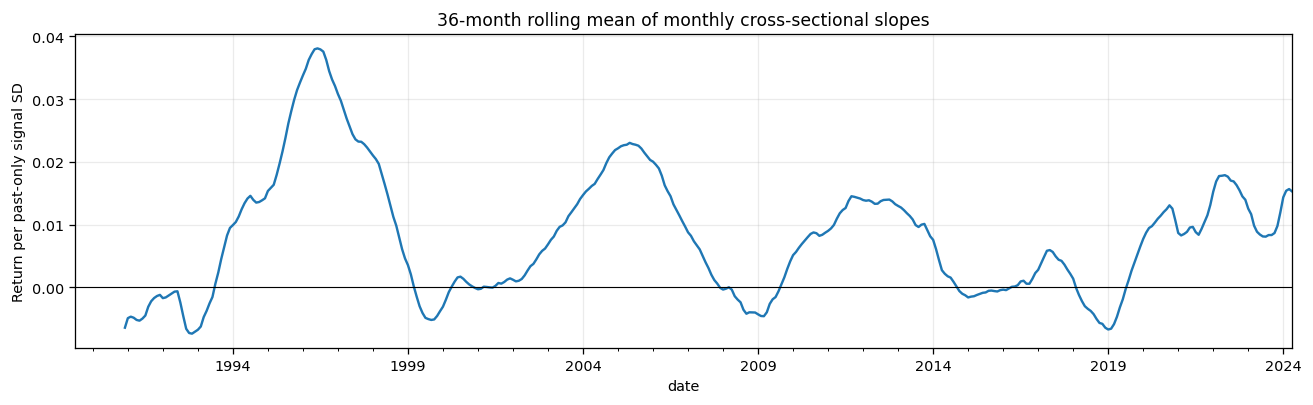

In [10]:
# ============================================================================
# FAMA–MACBETH
# ============================================================================
fmb_slopes, fmb_result = fmb_cross_section(p)
print(pd.Series(fmb_result).to_string())
print("\nCross-sectional slope quantiles:")
print(fmb_slopes["beta_cs"].quantile([0.05, 0.25, 0.50, 0.75, 0.95]).to_string())
print("Positive monthly slopes:",
      f"{(fmb_slopes['beta_cs'] > 0).sum()}/{len(fmb_slopes)}",
      f"({(fmb_slopes['beta_cs'] > 0).mean():.1%})")

fig, ax = plt.subplots(figsize=(11.5, 3.6))
fmb_slopes["beta_cs"].rolling(36, min_periods=18).mean().plot(ax=ax)
ax.axhline(0, color="black", lw=0.7)
ax.set_title("36-month rolling mean of monthly cross-sectional slopes")
ax.set_ylabel("Return per past-only signal SD")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "figure_fmb_rolling_slopes.png", bbox_inches="tight")
plt.show()


## 5. CCE-style leave-one-out mean-group regressions

For each country, the local return is regressed on the local signal and leave-one-out cross-sectional averages
of returns, signals, levels, and slopes. The averages are inferential controls, not tradable predictors.

This is a parsimonious **CCE-style** check, not a claim of implementing every dynamic CCE variant.


In [11]:
# ============================================================================
# CCE-STYLE MEAN GROUP
# ============================================================================
cce_rows = []
for country, g in p.groupby("country"):
    cols = ["tp_z_past", "global_tp_z_past_loo", "global_rx_loo",
            "global_y10_loo", "global_slope_loo"]
    d = g[["rx"] + cols].dropna()
    if len(d) < 60:
        continue
    b, se, r2, n = nw_ols(d["rx"], d[cols], lag=NW_LAG)
    cce_rows.append({
        "country": country,
        "beta_local": b[1],
        "NW_t_local": b[1] / se[1],
        "R2": r2,
        "n": n,
    })

cce = pd.DataFrame(cce_rows).set_index("country").sort_values("beta_local", ascending=False)
betas = cce["beta_local"].to_numpy()
mg_beta = betas.mean()
mg_se = betas.std(ddof=1) / np.sqrt(len(betas))
mg_t = mg_beta / mg_se
print(cce.to_string())
print(f"\nCCE-style mean-group local beta: {mg_beta:+.4f} | dispersion t = {mg_t:.2f}")
print("Positive local betas:", int((cce["beta_local"] > 0).sum()), "/", len(cce))


         beta_local  NW_t_local     R2    n
country                                    
NZL          0.0483      4.7421 0.8913  364
USA          0.0469      2.9150 0.7694  478
SWE          0.0302      3.2066 0.8940  208
GBR          0.0290      3.3579 0.7567  531
CAN          0.0259      3.9958 0.8226  531
AUS          0.0218      1.7999 0.8682  418
DEU          0.0164      2.5134 0.7845  531
NOR          0.0141      4.0010 0.9177  232

CCE-style mean-group local beta: +0.0291 | dispersion t = 6.46
Positive local betas: 8 / 8


## 6. Leave-one-country-out stability

This reruns the strongest pooled dependence control — country + time fixed effects with Driscoll–Kraay
inference — after omitting each country. Stability means the panel is not driven by one market; it does not
convert the remaining markets into independent observations.


In [12]:
# ============================================================================
# LEAVE-ONE-COUNTRY-OUT
# ============================================================================
loco_rows = []
countries = sorted(p["country"].unique())
for omitted in countries:
    d = p.loc[p["country"] != omitted]
    loco_rows.append({"omitted": omitted,
                      **panel_fe_dk(d, "rx", ["tp_z_past"], entity_fe=True, time_fe=True)})
loco = pd.DataFrame(loco_rows).set_index("omitted")
print(loco.to_string())
print("\nLOCO beta range:", f"{loco['beta'].min():+.4f}", "to", f"{loco['beta'].max():+.4f}")
print("LOCO positive coefficients:", int((loco["beta"] > 0).sum()), "/", len(loco))


          beta  se_DK   t_DK     n    T
omitted                                
AUS     0.0180 0.0039 4.5909  2933  532
CAN     0.0187 0.0039 4.7635  2820  532
CHE     0.0185 0.0038 4.8017  3293  532
DEU     0.0181 0.0044 4.1536  2820  532
GBR     0.0166 0.0039 4.2404  2820  532
NOR     0.0221 0.0042 5.2330  3119  532
NZL     0.0178 0.0041 4.3535  2987  532
SWE     0.0190 0.0039 4.9062  3143  532
USA     0.0177 0.0035 5.0413  2873  532

LOCO beta range: +0.0166 to +0.0221
LOCO positive coefficients: 9 / 9


## 7. Regime attribution

The same panel diagnostics are repeated over three pre-specified macro periods. The objective is not to
select the best window, but to reveal whether the cross-sectional result exists beyond the recent global
inflation cycle.


In [13]:
# ============================================================================
# SUBPERIODS
# ============================================================================
periods = {
    "pre_2008": (None, pd.Timestamp("2007-12-31")),
    "2008_2015": (pd.Timestamp("2008-01-31"), pd.Timestamp("2015-12-31")),
    "2016_plus": (pd.Timestamp("2016-01-31"), None),
}
period_rows = []
for label, (lo, hi) in periods.items():
    d = p.copy()
    if lo is not None:
        d = d.loc[d["date"] >= lo]
    if hi is not None:
        d = d.loc[d["date"] <= hi]
    if d["date"].nunique() < 36:
        continue
    tw = panel_fe_dk(d, "rx", ["tp_z_past"], entity_fe=True, time_fe=True)
    _, fm = fmb_cross_section(d)
    period_rows.append({
        "period": label,
        "start": str(d["date"].min().date()),
        "end": str(d["date"].max().date()),
        "countries": d["country"].nunique(),
        "months": d["date"].nunique(),
        "TWFE_beta": tw["beta"],
        "TWFE_t_DK": tw["t_DK"],
        "FMB_beta": fm["beta"],
        "FMB_t_NW": fm["t_NW"],
    })
period_table = pd.DataFrame(period_rows).set_index("period")
print(period_table.to_string())


                start         end  countries  months  TWFE_beta  TWFE_t_DK  FMB_beta  FMB_t_NW
period                                                                                        
pre_2008   1980-01-31  2007-12-31          8     336     0.0265     4.6697    0.0095    2.3562
2008_2015  2008-01-31  2015-12-31          8      96     0.0161     3.3608    0.0063    1.6408
2016_plus  2016-01-31  2024-04-30          9     100     0.0162     2.2146    0.0065    0.7730


## 8. Formal regime-interaction tests

The split-sample coefficients above are descriptive. This section estimates the three regime slopes jointly and tests their pairwise differences using the relevant HAC covariance: Driscoll–Kraay for the two-way-FE panel, Newey–West for the monthly Fama–MacBeth slopes, and Newey–West for the US time-series regression. The tests are pre-specified diagnostics; no claim of a structural regime break is made solely from these contrasts.


In [14]:
# ============================================================================
# FORMAL REGIME-INTERACTION TESTS
# ============================================================================
REGIME_ORDER = ["pre_2008", "2008_2015", "2016_plus"]

def regime_name(date):
    date = pd.Timestamp(date)
    if date <= pd.Timestamp("2007-12-31"):
        return "pre_2008"
    if date <= pd.Timestamp("2015-12-31"):
        return "2008_2015"
    return "2016_plus"

reg = p.copy()
reg["regime"] = reg["date"].map(regime_name)

interaction_cols = []
for label in REGIME_ORDER:
    col = f"tp_x_{label}"
    reg[col] = reg["tp_z_past"] * (reg["regime"] == label).astype(float)
    interaction_cols.append(col)

# A. Joint regime slopes under country + time FE with DK covariance.
twfe_regime_fit = panel_fe_dk_full(
    reg,
    y_col="rx",
    x_cols=interaction_cols,
    entity_fe=True,
    time_fe=True,
    lag=NW_LAG,
)

twfe_beta = twfe_regime_fit["beta"].copy()
twfe_beta.index = REGIME_ORDER
twfe_cov = twfe_regime_fit["cov_DK"].copy()
twfe_cov.index = REGIME_ORDER
twfe_cov.columns = REGIME_ORDER
twfe_se = np.sqrt(np.maximum(np.diag(twfe_cov), 0.0))

twfe_regime_slopes = pd.DataFrame({
    "model": "Panel TWFE + DK",
    "regime": REGIME_ORDER,
    "beta": twfe_beta.to_numpy(),
    "se": twfe_se,
    "t": twfe_beta.to_numpy() / twfe_se,
    "n": twfe_regime_fit["n"],
    "T": twfe_regime_fit["T"],
})

twfe_regime_tests = pairwise_wald_table(
    twfe_beta, twfe_cov, REGIME_ORDER, "Panel TWFE + DK"
)

# B. Joint regime means of the monthly Fama–MacBeth slope series.
fmb_reg = fmb_slopes.reset_index().copy()
fmb_reg["regime"] = fmb_reg["date"].map(regime_name)
fmb_X = np.column_stack([
    (fmb_reg["regime"] == label).astype(float).to_numpy()
    for label in REGIME_ORDER
])
fm_b, fm_se, fm_cov, _, fm_n = nw_ols(
    fmb_reg["beta_cs"].to_numpy(),
    fmb_X,
    lag=NW_LAG,
    add_intercept=False,
    return_cov=True,
)
fmb_regime_slopes = pd.DataFrame({
    "model": "Fama-MacBeth monthly slopes + NW",
    "regime": REGIME_ORDER,
    "beta": fm_b,
    "se": fm_se,
    "t": fm_b / fm_se,
    "n": fm_n,
    "T": fm_n,
})
fmb_regime_tests = pairwise_wald_table(
    fm_b, fm_cov, REGIME_ORDER, "Fama-MacBeth monthly slopes + NW"
)

# C. Joint US time-series regime slopes with NW covariance.
usa_reg = reg.loc[reg["country"] == "USA"].copy()
us_X = usa_reg[interaction_cols].to_numpy(float)
us_b, us_se, us_cov, us_r2, us_n = nw_ols(
    usa_reg["rx"].to_numpy(),
    us_X,
    lag=NW_LAG,
    add_intercept=True,
    return_cov=True,
)
us_beta = us_b[1:]
us_cov_slopes = us_cov[1:, 1:]
us_se_slopes = us_se[1:]

us_regime_slopes = pd.DataFrame({
    "model": "USA time series + NW",
    "regime": REGIME_ORDER,
    "beta": us_beta,
    "se": us_se_slopes,
    "t": us_beta / us_se_slopes,
    "n": us_n,
    "T": usa_reg["date"].nunique(),
})
us_regime_tests = pairwise_wald_table(
    us_beta, us_cov_slopes, REGIME_ORDER, "USA time series + NW"
)

regime_interaction_slopes = pd.concat(
    [twfe_regime_slopes, fmb_regime_slopes, us_regime_slopes],
    ignore_index=True,
)
regime_difference_tests = pd.concat(
    [twfe_regime_tests, fmb_regime_tests, us_regime_tests],
    ignore_index=True,
)

print("Joint regime-specific slopes")
print(
    regime_interaction_slopes
    .set_index(["model", "regime"])
    .to_string()
)
print("\nPairwise regime-difference tests")
print(
    regime_difference_tests
    .set_index(["model", "contrast"])
    .to_string()
)


Joint regime-specific slopes
                                             beta     se      t     n    T
model                            regime                                   
Panel TWFE + DK                  pre_2008  0.0197 0.0052 3.7766  3351  532
                                 2008_2015 0.0174 0.0037 4.7261  3351  532
                                 2016_plus 0.0169 0.0076 2.2394  3351  532
Fama-MacBeth monthly slopes + NW pre_2008  0.0095 0.0040 2.3562   418  418
                                 2008_2015 0.0063 0.0039 1.6408   418  418
                                 2016_plus 0.0065 0.0084 0.7730   418  418
USA time series + NW             pre_2008  0.1042 0.0210 4.9618   478  478
                                 2008_2015 0.0612 0.0201 3.0489   478  478
                                 2016_plus 0.0876 0.0288 3.0457   478  478

Pairwise regime-difference tests
                                                        difference     se       t  p_two_sided_normal
model     

## 9. Anchor-initialization sensitivity

The panel is rerun under the legacy draft ordering, where trend inflation is backfilled before entering the
real-rate EWMA. This is a named specification comparison, not an unreported fallback.


In [15]:
# ============================================================================
# INITIALIZATION SENSITIVITY
# ============================================================================
init_rows = []
for init in ["post_ewma_bfill", "draft_pre_rstar_bfill"]:
    objs = []
    for country, g in raw_panel.groupby("country"):
        d = g.sort_values("date").set_index("date").copy()
        d["country"] = country
        objs.append(run_country_objects(d, initialization=init))
    q = pd.concat(objs, ignore_index=True).dropna(subset=["rx", "tp_z_past"])
    tw = panel_fe_dk(q, "rx", ["tp_z_past"], entity_fe=True, time_fe=True)
    _, fm = fmb_cross_section(q)
    init_rows.append({
        "initialization": init,
        "TWFE_beta": tw["beta"],
        "TWFE_t_DK": tw["t_DK"],
        "FMB_beta": fm["beta"],
        "FMB_t_NW": fm["t_NW"],
        "countries": q["country"].nunique(),
        "observations": len(q),
    })
initialization_table = pd.DataFrame(init_rows).set_index("initialization")
print(initialization_table.to_string())


                       TWFE_beta  TWFE_t_DK  FMB_beta  FMB_t_NW  countries  observations
initialization                                                                          
post_ewma_bfill           0.0185     4.8351    0.0081    2.6134          9          3351
draft_pre_rstar_bfill     0.0190     4.8280    0.0079    2.4710          9          3351


## 10. Pre-specified automated reporting verdict

The code below translates the fixed reading rules into a compact reporting recommendation. It does not
alter any estimate.


In [16]:
# ============================================================================
# AUTOMATED REPORTING VERDICT
# ============================================================================
tw_beta = panel_table.loc["Country + time FE", "beta"]
tw_t = panel_table.loc["Country + time FE", "t_DK"]
fm_beta = fmb_result["beta"]
fm_t = fmb_result["t_NW"]
loco_all_positive = bool((loco["beta"] > 0).all())
post = period_table.loc["2016_plus"] if "2016_plus" in period_table.index else None

if tw_beta > 0 and tw_t > 1.645 and fm_beta > 0 and fm_t > 1.645:
    verdict = (
        "Evidence survives both time fixed effects and Fama–MacBeth inference: "
        "the panel contains predictive content beyond a purely global monthly episode."
    )
elif tw_beta > 0 and fm_beta > 0:
    verdict = (
        "Cross-sectional coefficients remain positive but are statistically marginal: "
        "report qualified evidence beyond the global component, not independent confirmation."
    )
else:
    verdict = (
        "The dependence-robust cross-sectional evidence does not survive: "
        "frame the panel as global comovement replication rather than independent confirmation."
    )

print(verdict)
print(f"TWFE: beta={tw_beta:+.4f}, DK t={tw_t:.2f}")
print(f"Fama–MacBeth: beta={fm_beta:+.4f}, NW t={fm_t:.2f}")
print("LOCO all positive:", loco_all_positive)
if post is not None:
    print(f"Post-2016 TWFE: beta={post['TWFE_beta']:+.4f}, DK t={post['TWFE_t_DK']:.2f}")


Evidence survives both time fixed effects and Fama–MacBeth inference: the panel contains predictive content beyond a purely global monthly episode.
TWFE: beta=+0.0185, DK t=4.84
Fama–MacBeth: beta=+0.0081, NW t=2.61
LOCO all positive: True
Post-2016 TWFE: beta=+0.0162, DK t=2.21


## 11. Decision rules for the paper

1. **Two-way FE and Fama–MacBeth both positive:** describe the panel as evidence beyond a purely global
   time-series episode.
2. **Country FE positive, two-way FE/Fama–MacBeth weak:** describe the panel as global comovement
   replication, not independent cross-country confirmation.
3. **CCE-style mean-group positive but heterogeneous:** report the sign count and failures; do not headline
   the mean-group t as if countries were independent.
4. **LOCO instability:** identify the influential country explicitly and downgrade the panel claim.
5. **Post-2016 concentration:** state it before any headline count and connect it to the US regime evidence.
6. The US zero-coupon 10Y result remains the primary identification result under every panel outcome.


In [17]:
# ============================================================================
# SAVE SNAPSHOTS, TABLES AND MANIFEST
# ============================================================================
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

raw_out = raw_panel.sort_values(["country", "date"]).copy()
model_out = model_panel.sort_values(["country", "date"]).copy()

raw_path = OUTPUT_DIR / SNAPSHOT_FILENAME
model_path = OUTPUT_DIR / MODEL_PANEL_FILENAME
raw_out.to_csv(raw_path, index=False)
model_out.to_csv(model_path, index=False)

baseline.to_csv(OUTPUT_DIR / "table_baseline_country_replication.csv")
dependence.to_csv(OUTPUT_DIR / "table_common_factor_diagnostics.csv")
panel_table.to_csv(OUTPUT_DIR / "table_panel_dk_models.csv")
fmb_slopes.to_csv(OUTPUT_DIR / "fmb_monthly_slopes.csv")
pd.DataFrame([fmb_result]).to_csv(OUTPUT_DIR / "table_fmb_summary.csv", index=False)
cce.to_csv(OUTPUT_DIR / "table_cce_style_mean_group.csv")
loco.to_csv(OUTPUT_DIR / "table_loco_twfe.csv")
period_table.to_csv(OUTPUT_DIR / "table_regime_attribution.csv")
regime_interaction_slopes.to_csv(
    OUTPUT_DIR / "table_regime_interaction_slopes.csv", index=False
)
regime_difference_tests.to_csv(
    OUTPUT_DIR / "table_regime_difference_tests.csv", index=False
)
initialization_table.to_csv(OUTPUT_DIR / "table_initialization_sensitivity.csv")

manifest = {
    "label": "macroanchor_panel09",
    "generated_utc": datetime.now(timezone.utc).isoformat(),
    "python_version": platform.python_version(),
    "pandas_version": pd.__version__,
    "panel_cutoff": str(PANEL_END.date()),
    "anchor_initialization": ANCHOR_INITIALIZATION,
    "pi_half_life_months": PI_HL,
    "rstar_half_life_months": RSTAR_HL,
    "minimum_estimation_months": MINW,
    "forecast_horizon_months": H,
    "included_countries": sorted(raw_out["country"].unique().tolist()),
    "excluded_or_unavailable": source_failures,
    "source_log": source_log,
    "raw_snapshot_filename": raw_path.name,
    "raw_snapshot_sha256_file": sha256_file(raw_path),
    "raw_snapshot_sha256_pandas": sha256_frame(raw_out),
    "model_panel_filename": model_path.name,
    "model_panel_sha256_file": sha256_file(model_path),
    "model_panel_sha256_pandas": sha256_frame(model_out),
    "notes": [
        "International target is duration-approximated 10Y excess return.",
        "Quarterly AUS/NZL CPI is dated at quarter-end plus one month and forward-filled; no linear interpolation is used.",
        "Regime slopes are estimated jointly and pairwise differences use DK or NW covariance as appropriate.",
        "Driscoll-Kraay and Fama-MacBeth are inferential dependence checks.",
        "CCE-style controls use leave-one-out cross-sectional averages.",
        "No country is treated as an independent replication draw in headline inference.",
    ],
}
manifest_path = OUTPUT_DIR / "panel09_manifest.json"
manifest_path.write_text(json.dumps(manifest, indent=2, default=str))

zip_path = shutil.make_archive(
    "/content/macroanchor_panel09_outputs",
    "zip",
    root_dir=OUTPUT_DIR.parent,
    base_dir=OUTPUT_DIR.name,
)

print("Saved output directory:", OUTPUT_DIR)
print("ZIP:", zip_path)
print("Raw snapshot SHA-256:", manifest["raw_snapshot_sha256_file"])
print("Model panel SHA-256:", manifest["model_panel_sha256_file"])

if AUTO_DOWNLOAD_ZIP:
    try:
        from google.colab import files
        files.download(zip_path)
    except Exception as e:
        print("Automatic download unavailable:", e)
        print("Download manually from:", zip_path)


Saved output directory: /content/macroanchor_panel09_outputs
ZIP: /content/macroanchor_panel09_outputs.zip
Raw snapshot SHA-256: 3f0c2581db5ffe3f23580da83db42f726dc9b3832d59ca13dd5779ba1db71caf
Model panel SHA-256: 1628c4eaff487f6d87cc93fe62c7af909850d9ceedf448d9d8321f8b8477bbf6


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>